# 04 - Entrenamiento y optimización

Se entrenan varios modelos de clasificación, se optimizan sus hiperparámetros y se elige el que mejor predice `smoking` según el **F1 de la clase 1**. El modelo principal es **XGBoost**, comparado contra los otros modelos clásicos.

Se usa solo `train.csv` (~40.000 filas). `valid.csv` queda reservado para la notebook 05.

Pasos:
1. Lectura y chequeo de representatividad train vs validación.
2. Línea base y comparación de modelos con valores por defecto.
3. Optimización de hiperparámetros de cada modelo.
4. Elección del modelo y del umbral de decisión.
5. Entrenamiento final, guardado en `models/` y caracterización.

En cada experimento se reporta el **F1 en train y en validación cruzada (CV)**. La diferencia entre ambos (**brecha**) indica sobreajuste. La validación cruzada es **por grupo**: las dos copias de una persona duplicada (ver 03) siempre quedan del mismo lado, así que el F1 de CV mide el rendimiento en **personas nuevas**.

#### Dependencias

In [1]:
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp, loguniform, randint, uniform

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

import utils  # notebooks/utils.py: agrupa los registros duplicados

#### Parametros

In [2]:
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")

RANDOM_STATE = 42
N_FOLDS = 5
N_JOBS = -1  # usa todos los nucleos

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

#### Funciones

- `fit_and_score`: entrena un modelo con validación cruzada por grupo y devuelve F1 train, F1 CV, desvío entre folds y brecha.
- `barrer_hiperparametro`: aplica `fit_and_score` a cada valor de un hiperparámetro.

In [3]:
def fit_and_score(modelo, X, y):
    inicio = time.time()
    r = cross_validate(modelo, X, y, groups=GRUPOS, cv=cv, scoring="f1", return_train_score=True, n_jobs=N_JOBS)
    return {
        "F1 train": r["train_score"].mean(),
        "F1 CV": r["test_score"].mean(),
        "desvio CV": r["test_score"].std(),
        "brecha": r["train_score"].mean() - r["test_score"].mean(),
        "segundos": time.time() - inicio,
    }


def barrer_hiperparametro(crear_modelo, valores):
    # Un modelo por cada valor del hiperparametro; se guardan sus metricas
    filas = {}
    for v in valores:
        filas[v] = fit_and_score(crear_modelo(v), X_train, y_train)
    return pd.DataFrame(filas).T


def graficar_curva(res, nombre_param, titulo, log_x=False):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(res.index, res["F1 train"], marker="o", label="F1 train")
    ax.errorbar(res.index, res["F1 CV"], yerr=res["desvio CV"], marker="o", capsize=3, label="F1 CV")
    if log_x:
        ax.set_xscale("log")
    ax.set_xlabel(nombre_param); ax.set_ylabel("F1 clase 1"); ax.set_title(titulo); ax.legend()
    plt.tight_layout(); plt.show()


def registrar(modelo, config, metricas):
    experimentos.append({"modelo": modelo, "config": config, **metricas})

## 1. Lectura

Datos limpios generados por la notebook 03. `columnas.json` define las features y las columnas que llevan `log1p` en los modelos lineales.

In [4]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
columnas = json.loads((PROCESSED_DIR / "columnas.json").read_text())

FEATURES = columnas["features"]
COLS_LOG = columnas["cols_log"]
TARGET = columnas["target"]

X_train = train[FEATURES]
y_train = train[TARGET]
GRUPOS = utils.grupos_duplicados(train, FEATURES)  # una persona duplicada = un grupo

print("X_train:", X_train.shape)
print("% fumadores:", round(y_train.mean(), 4))
print("Personas distintas:", len(np.unique(GRUPOS)), "| filas que son copia de otra:", len(GRUPOS) - len(np.unique(GRUPOS)))

X_train: (39999, 24)
% fumadores: 0.3669
Personas distintas: 35642 | filas que son copia de otra: 4357


## 2. ¿Train y validación tienen la misma distribución?

Test de **Kolmogorov-Smirnov** por feature (H0: misma distribución). Solo se comparan features, sin usar el target de validación.

In [5]:
valid_features = pd.read_csv(PROCESSED_DIR / "valid.csv", usecols=FEATURES)

ks = []
for columna in FEATURES:
    statistic, p_value = ks_2samp(X_train[columna], valid_features[columna])
    ks.append({"columna": columna, "estadistico": statistic, "p_value": p_value})
ks = pd.DataFrame(ks).set_index("columna")

print("Columnas con p-value < 0.05:", (ks["p_value"] < 0.05).sum(), "de", len(ks))
ks.sort_values("p_value").round(4).head(5)

Columnas con p-value < 0.05: 2 de 24


,estadistico,p_value
columna,,
cholesterol,0.0179,0.0117
age,0.0154,0.0436
triglyceride,0.0149,0.0567
ldl,0.0144,0.0728
alt,0.0136,0.1012


Dos columnas (`cholesterol` y `age`) dan p < 0,05. Con 24 tests al 5% se esperan ~1,2 por azar, y los estadísticos son muy chicos (≤ 0,018): las distribuciones son prácticamente iguales. Lo medido en CV debería trasladarse a validación.

## 3. Validación cruzada y línea base

- **Validación cruzada estratificada y por grupo de 5 folds** (`StratifiedGroupKFold`) sobre train. Mantiene la proporción de fumadores en cada fold y nunca separa a una persona duplicada. Todos los modelos usan los mismos folds, así que la comparación es directa.
- **Línea base:** predecir que todos fuman da F1 ≈ 0,54. Es el piso a superar.

In [6]:
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
experimentos = []  # se registra cada intento -> models/resultados_cv.csv

res_base = fit_and_score(DummyClassifier(strategy="constant", constant=1), X_train, y_train)
registrar("Linea base (todos fuman)", "-", res_base)
pd.Series(res_base).round(4)

,0
F1 train,0.5369
F1 CV,0.5369
desvio CV,0.0061
brecha,0.0000
segundos,7.5600


## 4. Comparación inicial con valores por defecto

| Modelo | Preprocesamiento | Desbalance |
|---|---|---|
| Regresión logística | `log1p` + `StandardScaler` | `class_weight="balanced"` |
| KNN | `log1p` + `StandardScaler` | — (no tiene la opción) |
| Árbol de decisión | — | `class_weight="balanced"` |
| Random Forest | — | `class_weight="balanced"` |
| **XGBoost** | — | `scale_pos_weight` = no fumadores / fumadores |

- Los modelos basados en distancias o coeficientes necesitan escala. Los de árboles no.
- El preprocesamiento va dentro de un pipeline: se ajusta solo con los folds de entrenamiento, sin fuga de información.
- El desbalance (37% fumadores) se maneja con pesos. No se eliminan ni se duplican filas. En XGBoost, `scale_pos_weight` ≈ 1,73 hace que cada error sobre un fumador pese 1,73 veces más: es el equivalente de `class_weight="balanced"`.

In [7]:
SCALE_POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(SCALE_POS_WEIGHT, 3))


def preprocesador_lineal():
    # log1p en las variables asimetricas + escalado; se ajusta dentro de cada fold
    log = ColumnTransformer(
        [("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), COLS_LOG)],
        remainder="passthrough",
    )
    return make_pipeline(log, StandardScaler())


def crear_logistica(C=1.0):
    return make_pipeline(preprocesador_lineal(),
                         LogisticRegression(C=C, class_weight="balanced", max_iter=2000))


def crear_knn(k=5):
    return make_pipeline(preprocesador_lineal(), KNeighborsClassifier(n_neighbors=k))


def crear_arbol(max_depth=None):
    return DecisionTreeClassifier(max_depth=max_depth, class_weight="balanced", random_state=RANDOM_STATE)


def crear_rf(min_samples_leaf=1):
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=min_samples_leaf,
                                  class_weight="balanced", random_state=RANDOM_STATE, n_jobs=N_JOBS)


def crear_xgboost(**params):
    return XGBClassifier(tree_method="hist", scale_pos_weight=SCALE_POS_WEIGHT, eval_metric="logloss",
                         random_state=RANDOM_STATE, n_jobs=2, **params)

scale_pos_weight: 1.725


In [8]:
%%time
modelos_default = {
    "Regresion logistica": crear_logistica(),
    "KNN": crear_knn(),
    "Arbol de decision": crear_arbol(),
    "Random Forest": crear_rf(),
    "XGBoost": crear_xgboost(),
}
res_default = {}
for nombre, modelo in modelos_default.items():
    res_default[nombre] = fit_and_score(modelo, X_train, y_train)
    registrar(nombre, "por defecto", res_default[nombre])

res_default = pd.DataFrame(res_default).T
res_default.round(4)

Wall time: 56.6 s


,F1 train,F1 CV,desvio CV,brecha,segundos
Regresion logistica,0.7110,0.7101,0.0063,0.0009,6.9312
KNN,0.7558,0.6025,0.0051,0.1533,16.1073
Arbol de decision,1.0000,0.5638,0.0079,0.4362,7.1079
Random Forest,1.0000,0.6704,0.0078,0.3296,19.9986
XGBoost,0.8314,0.7001,0.0075,0.1313,6.4558


- Todos superan la línea base.
- Árbol y Random Forest llegan a **F1 train = 1,0** pero en CV dan 0,56 y 0,67: memorizan train y no generalizan.
- **XGBoost por defecto también sobreajusta** (0,83 en train vs 0,70 en CV): usa árboles de profundidad 6 y una tasa de aprendizaje alta (0,3).
- KNN con `k=5` sobreajusta (0,76 vs 0,60).
- La logística no tiene brecha (0,711 vs 0,710) y, con valores por defecto, es la mejor.

Hace falta optimizar hiperparámetros antes de comparar.

## 5. Optimización de hiperparámetros

Para cada modelo se recorre su hiperparámetro principal. XGBoost, que tiene varios hiperparámetros que interactúan, se optimiza con búsqueda aleatoria.

**Criterio de elección:** el valor con **mejor F1 CV**. Como la validación cruzada es por grupo, ese F1 mide el rendimiento en personas nuevas: un modelo que memoriza no puede ganar. Igual se controla que la brecha train - CV sea chica.

### 5.1 Regresión logística: `C`

`C` más chico = más regularización.

C elegido: 0.01
Wall time: 30.1 s


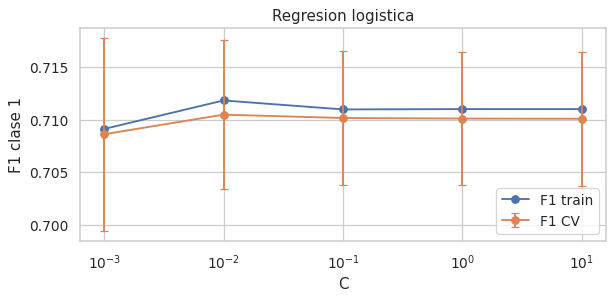

,F1 train,F1 CV,desvio CV,brecha,segundos
0.001,0.7091,0.7086,0.0092,0.0005,6.0434
0.010,0.7118,0.7105,0.0071,0.0013,6.0013
0.100,0.7110,0.7101,0.0063,0.0008,5.9481
1.000,0.7110,0.7101,0.0063,0.0009,6.0036
10.000,0.7110,0.7101,0.0064,0.0009,5.9393


In [9]:
%%time
res_log = barrer_hiperparametro(crear_logistica, [0.001, 0.01, 0.1, 1, 10])
mejor_C = res_log["F1 CV"].idxmax()
registrar("Regresion logistica", f"C={mejor_C}", res_log.loc[mejor_C].to_dict())

graficar_curva(res_log, "C", "Regresion logistica", log_x=True)
print("C elegido:", mejor_C)
res_log.round(4)

### 5.2 KNN: `k`

`k` más grande = frontera más suave.

k elegido: 201
Wall time: 81.3 s


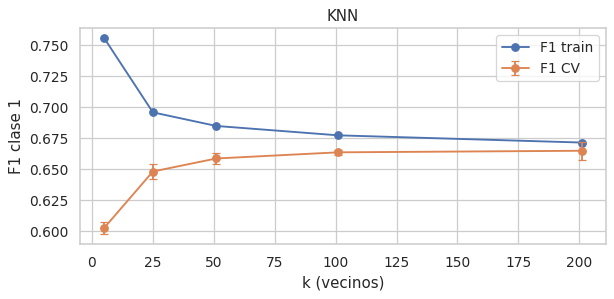

,F1 train,F1 CV,desvio CV,brecha,segundos
5,0.7558,0.6025,0.0051,0.1533,14.8001
25,0.6958,0.6481,0.0061,0.0477,15.2631
51,0.6848,0.6586,0.0047,0.0262,15.7769
101,0.6773,0.6636,0.0022,0.0137,16.7006
201,0.6715,0.6648,0.0073,0.0066,18.7122


In [10]:
%%time
res_knn = barrer_hiperparametro(crear_knn, [5, 25, 51, 101, 201])
mejor_k = res_knn["F1 CV"].idxmax()
registrar("KNN", f"k={mejor_k}", res_knn.loc[mejor_k].to_dict())

graficar_curva(res_knn, "k (vecinos)", "KNN")
print("k elegido:", mejor_k)
res_knn.round(4)

### 5.3 Árbol de decisión: `max_depth`

A más profundidad sube el F1 en train, pero a partir de cierto punto el F1 en CV baja: ahí empieza el sobreajuste.

max_depth elegido: 4
Wall time: 55.1 s


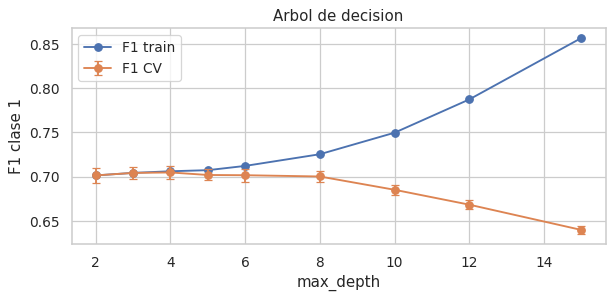

,F1 train,F1 CV,desvio CV,brecha,segundos
2,0.7013,0.7013,0.0081,0.0000,5.9749
3,0.7041,0.7041,0.0069,0.0000,5.8716
4,0.7060,0.7046,0.0074,0.0014,6.0279
5,0.7072,0.7018,0.0062,0.0054,5.9870
6,0.7120,0.7015,0.0072,0.0105,6.0513
8,0.7252,0.7000,0.0060,0.0252,6.2423
10,0.7496,0.6850,0.0059,0.0645,6.2437
12,0.7872,0.6682,0.0053,0.1190,6.4116
15,0.8566,0.6396,0.0047,0.2170,6.2887


In [11]:
%%time
res_arbol = barrer_hiperparametro(crear_arbol, [2, 3, 4, 5, 6, 8, 10, 12, 15])
mejor_depth = res_arbol["F1 CV"].idxmax()
registrar("Arbol de decision", f"max_depth={mejor_depth}", res_arbol.loc[mejor_depth].to_dict())

graficar_curva(res_arbol, "max_depth", "Arbol de decision")
print("max_depth elegido:", mejor_depth)
res_arbol.round(4)

### 5.4 Random Forest: `min_samples_leaf`

Con 1, cada árbol puede aislar a una sola persona. Valores mayores obligan a agrupar y regularizan. Se usan 300 árboles.

min_samples_leaf elegido: 10
Wall time: 115.8 s


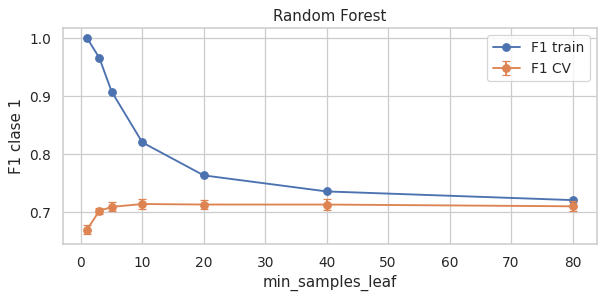

,F1 train,F1 CV,desvio CV,brecha,segundos
1,1.0000,0.6704,0.0078,0.3296,20.1532
3,0.9659,0.7025,0.0053,0.2634,18.7886
5,0.9080,0.7095,0.0077,0.1985,17.7142
10,0.8204,0.7145,0.0084,0.1059,16.4053
20,0.7637,0.7135,0.0072,0.0501,15.4239
40,0.7361,0.7135,0.0087,0.0226,14.2041
80,0.7212,0.7105,0.0087,0.0107,13.0349


In [12]:
%%time
res_rf = barrer_hiperparametro(crear_rf, [1, 3, 5, 10, 20, 40, 80])
mejor_hoja = res_rf["F1 CV"].idxmax()
registrar("Random Forest", f"n_estimators=300, min_samples_leaf={mejor_hoja}", res_rf.loc[mejor_hoja].to_dict())

graficar_curva(res_rf, "min_samples_leaf", "Random Forest")
print("min_samples_leaf elegido:", mejor_hoja)
res_rf.round(4)

### 5.5 XGBoost: búsqueda aleatoria

`RandomizedSearchCV` prueba **40 combinaciones** al azar de estos rangos, con los mismos folds por grupo y `return_train_score=True` para ver la brecha:

| Hiperparámetro | Qué controla | Rango |
|---|---|---|
| `n_estimators` | cantidad de árboles (rondas de boosting) | 100 – 800 |
| `max_depth` | profundidad de cada árbol | 2 – 10 |
| `learning_rate` | cuánto corrige cada árbol (eta) | 0,01 – 0,2 |
| `gamma` | mejora mínima para hacer un corte | 0 – 2 |
| `min_child_weight` | peso mínimo en cada hoja | 1 – 29 |
| `subsample` | % de filas por árbol | 60% – 100% |
| `colsample_bytree` | % de columnas por árbol | 50% – 100% |
| `reg_lambda` | penalización L2 | 0,1 – 10 |

In [13]:
%%time
distribuciones = {
    "n_estimators": [100, 200, 400, 600, 800],
    "max_depth": randint(2, 11),
    "learning_rate": loguniform(0.01, 0.2),
    "gamma": uniform(0, 2),
    "min_child_weight": randint(1, 30),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.5, 0.5),
    "reg_lambda": loguniform(0.1, 10),
}
model_search = RandomizedSearchCV(crear_xgboost(), distribuciones, n_iter=40, scoring="f1", cv=cv,
                                  return_train_score=True, random_state=RANDOM_STATE, n_jobs=8)
model_search.fit(X_train, y_train, groups=GRUPOS)

res_xgb = pd.DataFrame(model_search.cv_results_)
res_xgb = pd.DataFrame({
    "F1 train": res_xgb["mean_train_score"], "F1 CV": res_xgb["mean_test_score"],
    "desvio CV": res_xgb["std_test_score"],
    "brecha": res_xgb["mean_train_score"] - res_xgb["mean_test_score"],
    "params": res_xgb["params"],
}).sort_values("F1 CV", ascending=False)
res_xgb.head(8).round(4)

Wall time: 86.4 s


,F1 train,F1 CV,desvio CV,brecha,params
17,0.7355,0.7179,0.0066,0.0176,"{'colsample_bytree': 0.7553736512887829, 'gamma': 0.834822006297558, 'learning_rate': 0.019452208847287395, 'max_dep..."
32,0.7268,0.7172,0.0062,0.0096,"{'colsample_bytree': 0.8974056517708242, 'gamma': 1.0052741862103842, 'learning_rate': 0.05630789064671439, 'max_dep..."
4,0.7349,0.7168,0.0067,0.0181,"{'colsample_bytree': 0.8037724259507192, 'gamma': 0.34104824737458306, 'learning_rate': 0.012151617026673379, 'max_d..."
34,0.7283,0.7167,0.0057,0.0115,"{'colsample_bytree': 0.6653751523352569, 'gamma': 1.1055299336709798, 'learning_rate': 0.05553536987443605, 'max_dep..."
39,0.7362,0.7164,0.0061,0.0198,"{'colsample_bytree': 0.7894324477537793, 'gamma': 0.8769482460361739, 'learning_rate': 0.0748731595003309, 'max_dept..."
11,0.7758,0.7163,0.0063,0.0595,"{'colsample_bytree': 0.811649063413779, 'gamma': 0.6617960497052984, 'learning_rate': 0.012097379927033842, 'max_dep..."
14,0.7505,0.7159,0.0065,0.0346,"{'colsample_bytree': 0.9537832369630466, 'gamma': 0.4985844582977499, 'learning_rate': 0.03419168411765895, 'max_dep..."
30,0.7299,0.7158,0.0058,0.0140,"{'colsample_bytree': 0.5894113546106644, 'gamma': 0.7329375691657198, 'learning_rate': 0.0929368979269672, 'max_dept..."


Se queda la mejor combinación (`model_search.best_estimator_`) y se controla su brecha.

In [14]:
best_model = model_search.best_estimator_
elegido_xgb = res_xgb.loc[model_search.best_index_]
params_xgb = {k: (round(float(v), 4) if isinstance(v, float) else int(v)) for k, v in model_search.best_params_.items()}

registrar("XGBoost", json.dumps(params_xgb), elegido_xgb.drop("params").to_dict())

print("Mejor combinacion -> F1 train:", round(elegido_xgb["F1 train"], 4), "| F1 CV:", round(elegido_xgb["F1 CV"], 4),
      "| brecha:", round(elegido_xgb["brecha"], 4))
pd.Series(params_xgb).to_frame("valor elegido")

Mejor combinacion -> F1 train: 0.7355 | F1 CV: 0.7179 | brecha: 0.0176


,valor elegido
colsample_bytree,0.7554
gamma,0.8348
learning_rate,0.0195
max_depth,4.0000
min_child_weight,10.0000
n_estimators,600.0000
reg_lambda,0.3078
subsample,0.6673


- La mejor combinación usa **600 árboles chicos** (`max_depth=4`) que aprenden de a poco (`learning_rate=0,02`), con hojas de peso mínimo 10 y dos tercios de las filas por árbol (`subsample=0,67`). Esto regulariza el modelo.
- **F1 train 0,736 vs CV 0,718: brecha de 0,018, sin sobreajuste.** Por defecto la brecha era 0,13.
- Los valores elegidos no quedan en el borde de sus rangos (`max_depth` 4 de 2–10, `min_child_weight` 10 de 1–29, 600 de 100–800 árboles).
- Las 8 mejores combinaciones dan entre 0,716 y 0,718: el resultado es estable y no depende de una combinación afortunada.

## 6. Comparación final y elección

Mejor configuración de cada modelo. Se elige el de mejor F1 CV, y se muestra cuáles quedan a menos de 1 desvío (diferencia no significativa).

In [15]:
resultados = pd.DataFrame(experimentos)
finales = resultados[resultados["config"] != "por defecto"].drop_duplicates("modelo", keep="last").set_index("modelo")
finales = finales.sort_values("F1 CV", ascending=False)
finales[["config", "F1 train", "F1 CV", "desvio CV", "brecha"]].round(4)

,config,F1 train,F1 CV,desvio CV,brecha
modelo,,,,,
XGBoost,"{""colsample_bytree"": 0.7554, ""gamma"": 0.8348, ""learning_rate"": 0.0195, ""max_depth"": 4, ""min_child_weight"": 10, ""n_es...",0.7355,0.7179,0.0066,0.0176
Random Forest,"n_estimators=300, min_samples_leaf=10",0.8204,0.7145,0.0084,0.1059
Regresion logistica,C=0.01,0.7118,0.7105,0.0071,0.0013
Arbol de decision,max_depth=4,0.7060,0.7046,0.0074,0.0014
KNN,k=201,0.6715,0.6648,0.0073,0.0066
Linea base (todos fuman),-,0.5369,0.5369,0.0061,0.0000


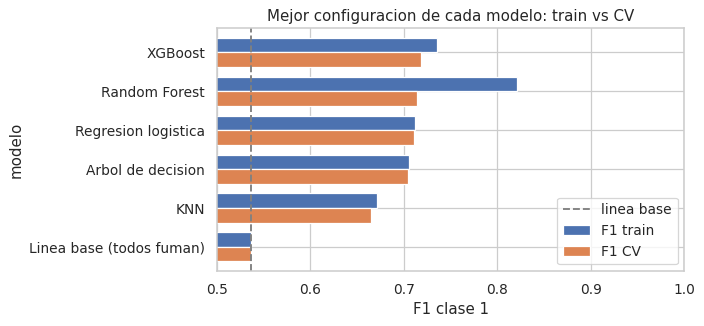

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.8))
finales[["F1 train", "F1 CV"]].plot.barh(ax=ax, width=0.75)
ax.axvline(res_base["F1 CV"], color="gray", ls="--", label="linea base")
ax.set_xlim(0.5, 1.0); ax.invert_yaxis(); ax.set_xlabel("F1 clase 1")
ax.set_title("Mejor configuracion de cada modelo: train vs CV"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [17]:
candidatos = finales.drop(index="Linea base (todos fuman)")
mejor = candidatos["F1 CV"].idxmax()
empatados = candidatos[candidatos["F1 CV"] >= candidatos.loc[mejor, "F1 CV"] - candidatos.loc[mejor, "desvio CV"]]
MODELO_ELEGIDO = mejor

print("ELEGIDO (mejor F1 CV):", MODELO_ELEGIDO, round(candidatos.loc[mejor, "F1 CV"], 4))
print("A menos de 1 desvio del elegido:", [m for m in empatados.index if m != mejor])

ELEGIDO (mejor F1 CV): XGBoost 0.7179
A menos de 1 desvio del elegido: ['Random Forest']


In [18]:
constructores = {
    "Regresion logistica": lambda: crear_logistica(mejor_C),
    "KNN": lambda: crear_knn(mejor_k),
    "Arbol de decision": lambda: crear_arbol(mejor_depth),
    "Random Forest": lambda: crear_rf(mejor_hoja),
    "XGBoost": lambda: crear_xgboost(**params_xgb),
}
modelo_final = constructores[MODELO_ELEGIDO]()
modelo_final

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7554, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0.8348,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.0195, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=10, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=600, n_jobs=2,
              num_parallel_tree=None, ...)

- **XGBoost tiene el mejor F1 CV (0,718) y casi no sobreajusta** (brecha 0,018).
- Random Forest (0,715) queda a menos de 1 desvío, pero memoriza bastante más (brecha 0,11).
- Logística (0,711), árbol (0,705) y KNN (0,665) quedan detrás.

Las diferencias entre los mejores son chicas: en personas nuevas, los modelos de árboles bien regularizados y la logística rinden entre 0,71 y 0,72. XGBoost queda primero y es el que mejor combina rendimiento y poca brecha.

## 7. Umbral de decisión

El modelo devuelve una probabilidad y, por defecto, clasifica como fumador a partir de 0,50. Moviendo el umbral se cambia el balance entre precisión y recall, y con eso el F1.

El umbral se elige con **predicciones out-of-fold** sobre train (`cross_val_predict` con los mismos folds por grupo): cada persona recibe la probabilidad de un modelo que no la vio al entrenar. Así el umbral no se ajusta sobre los datos con los que se mide en la 05.

In [19]:
%%time
proba_oof = cross_val_predict(modelo_final, X_train, y_train, groups=GRUPOS, cv=cv,
                              method="predict_proba", n_jobs=N_JOBS)[:, 1]

umbrales = np.round(np.arange(0.20, 0.81, 0.01), 2)
curva_umbral = pd.DataFrame({
    "precision": [precision_score(y_train, proba_oof >= u) for u in umbrales],
    "recall": [recall_score(y_train, proba_oof >= u) for u in umbrales],
    "F1": [f1_score(y_train, proba_oof >= u) for u in umbrales],
}, index=umbrales)

UMBRAL = float(curva_umbral["F1"].idxmax())
print(f"Umbral elegido: {UMBRAL}")
curva_umbral.loc[sorted({0.5, UMBRAL})].round(4)

Umbral elegido: 0.49
Wall time: 10.2 s


,precision,recall,F1
0.49,0.6034,0.8859,0.7178
0.50,0.6061,0.8786,0.7173


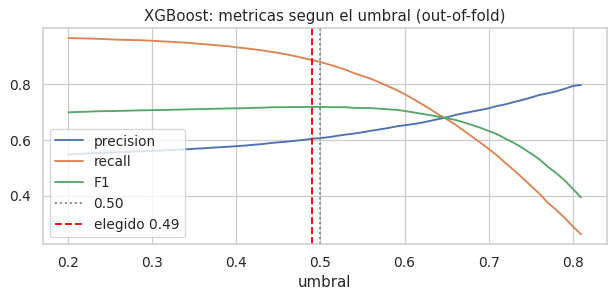

In [20]:
fig, ax = plt.subplots(figsize=(7, 3.5))
curva_umbral.plot(ax=ax)
ax.axvline(0.5, color="gray", ls=":", label="0.50")
ax.axvline(UMBRAL, color="red", ls="--", label=f"elegido {UMBRAL}")
ax.set_xlabel("umbral"); ax.set_title(f"{MODELO_ELEGIDO}: metricas segun el umbral (out-of-fold)"); ax.legend()
plt.tight_layout(); plt.show()

- Bajar el umbral aumenta el recall y reduce la precisión. Subirlo hace lo contrario.
- El óptimo (0,49) es prácticamente 0,50 (F1 0,7178 vs 0,7173), porque `scale_pos_weight` ya corrige el desbalance.
- La curva es plana cerca del máximo, así que el valor elegido es estable.

## 8. Entrenamiento final y guardado

El modelo elegido se reentrena con todo train.

| Archivo | Contenido |
|---|---|
| `models/modelo_final.joblib` | modelo entrenado |
| `models/umbral.json` | modelo, configuración, umbral, features y F1 CV |
| `models/resultados_cv.csv` | todos los experimentos de esta notebook |

In [21]:
%%time
modelo_final.fit(X_train, y_train)

MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(modelo_final, MODELS_DIR / "modelo_final.joblib", compress=3)

config_final = {
    "modelo": MODELO_ELEGIDO,
    "config": finales.loc[MODELO_ELEGIDO, "config"],
    "umbral": UMBRAL,
    "features": FEATURES,
    "f1_cv": round(float(finales.loc[MODELO_ELEGIDO, "F1 CV"]), 4),
    "f1_oof_con_umbral": round(float(curva_umbral.loc[UMBRAL, "F1"]), 4),
}
(MODELS_DIR / "umbral.json").write_text(json.dumps(config_final, indent=2))
pd.DataFrame(experimentos).to_csv(MODELS_DIR / "resultados_cv.csv", index=False)

for f in sorted(MODELS_DIR.iterdir()):
    print(f"{f.name:28s} {f.stat().st_size / 1e6:6.2f} MB")

metricas_validacion.json       0.00 MB
modelo_final.joblib            0.24 MB
resultados_cv.csv              0.00 MB
umbral.json                    0.00 MB
Wall time: 1.1 s


In [22]:
# Chequeo: el modelo guardado se carga y predice igual
recargado = joblib.load(MODELS_DIR / "modelo_final.joblib")
p_original = modelo_final.predict_proba(X_train)[:, 1]
p_recargado = recargado.predict_proba(X_train)[:, 1]
print("Probabilidades iguales (tolerancia 1e-9):", np.allclose(p_original, p_recargado, atol=1e-9))
print("Mismas clases con el umbral:", np.array_equal(p_original >= UMBRAL, p_recargado >= UMBRAL))

Probabilidades iguales (tolerancia 1e-9): True
Mismas clases con el umbral: True


## 9. Caracterización del modelo

Perfil de las personas que el modelo clasifica como fumadoras. Se usan las predicciones out-of-fold con el umbral elegido y **solo las variables que usa el modelo**: proporciones en las binarias y medianas en las continuas.

In [23]:
caracterizacion = X_train.copy()
caracterizacion["prediccion"] = np.where(proba_oof >= UMBRAL, "fumador", "no fumador")
caracterizacion["smoking real"] = y_train.values

print(caracterizacion["prediccion"].value_counts().to_frame("personas"))

            personas
prediccion          
fumador        21549
no fumador     18450


In [24]:
binarias = columnas["binarias"]
caracterizacion.groupby("prediccion")[binarias].mean().mul(100).round(1).T.add_suffix(" (%)")

prediccion,fumador (%),no fumador (%)
gender,99.9,21.0
tartar,62.0,48.1
dental_caries,26.7,15.3


In [25]:
continuas = [c for c in FEATURES if c not in binarias]
medianas = caracterizacion.groupby("prediccion")[continuas].median().T
medianas["diferencia %"] = ((medianas["fumador"] / medianas["no fumador"] - 1) * 100).round(1)
medianas.sort_values("diferencia %", key=abs, ascending=False).head(12)

prediccion,fumador,no fumador,diferencia %
gtp,36.0,18.0,100.0
triglyceride,131.0,86.0,52.3
alt,25.0,18.0,38.9
weight_kg,70.0,55.0,27.3
serum_creatinine,1.0,0.8,25.0
hdl,51.0,60.0,-15.0
hemoglobin,15.5,13.6,14.0
age,40.0,45.0,-11.1
height_cm,170.0,155.0,9.7
ast,24.0,22.0,9.1


In [26]:
# Como se comporta el modelo dentro de cada genero (out-of-fold)
por_genero = []
for g, nombre in [(1, "hombres"), (0, "mujeres")]:
    sub = caracterizacion[caracterizacion["gender"] == g]
    pred = sub["prediccion"] == "fumador"
    real = sub["smoking real"] == 1
    por_genero.append({
        "genero": nombre, "personas": len(sub), "fumadores reales": int(real.sum()),
        "% predichos fumadores": round(pred.mean() * 100, 1),
        "recall (fumadores detectados)": round((pred & real).sum() / real.sum(), 3),
    })
pd.DataFrame(por_genero).set_index("genero")

,personas,fumadores reales,% predichos fumadores,recall (fumadores detectados)
genero,,,,
hombres,25410,14056,84.7,0.925
mujeres,14589,621,0.1,0.010


**Perfil de los clasificados como fumadores:** prácticamente todos hombres (99,9%), con más sarro (62% vs 48%) y caries (27% vs 15%), algo más jóvenes (40 vs 45 años), GTP al doble (36 vs 18), más triglicéridos (131 vs 86), más ALT y hemoglobina, y menos HDL (51 vs 60).

**Limitación:** el modelo casi nunca clasifica como fumadora a una mujer. Detecta ~1% de las fumadoras (recall 0,010), contra 92,5% de los fumadores hombres. Con solo ~4% de fumadoras entre las mujeres, al modelo le conviene clasificarlas a todas como no fumadoras. El F1 global depende casi por completo de los hombres.

Que una variable separe los grupos no implica causalidad: altura y hemoglobina reflejan en buena parte el sexo. La importancia de cada variable se evalúa en la 05.

## 10. Conclusiones

| Tema | Resultado |
|---|---|
| Método | 5 modelos comparados con CV estratificada y por grupo (5 folds) sobre train, optimizando F1 de la clase 1 |
| Modelo elegido | **XGBoost**: 600 árboles de profundidad 4, `learning_rate=0,02`, `min_child_weight=10`, `subsample=0,67`, `colsample_bytree=0,76`, `scale_pos_weight=1,73` |
| F1 CV | **0,718** (desvío 0,007). Umbral 0,49 (out-of-fold) |
| Sobreajuste | **No:** train 0,736 vs CV 0,718 (brecha 0,018). Por defecto XGBoost sí sobreajustaba (0,83 vs 0,70) y se corrigió optimizando |
| Desbalance | Sin undersampling ni oversampling: `scale_pos_weight` + umbral |
| Alternativa | Random Forest (0,715) empata estadísticamente pero memoriza más (brecha 0,11) |
| Limitación | Casi no detecta mujeres fumadoras |

**Por qué la validación cruzada es por grupo:** el dataset tiene registros duplicados de la misma persona (ver 03). Con una CV común, una copia queda en entrenamiento y la otra en evaluación, y eso premia a los modelos que memorizan (árboles muy profundos) aunque rindan peor con personas nuevas. Separando por grupo, el F1 de CV mide lo que importa: cómo predice el modelo a alguien que nunca vio.

**Resumen de experimentos** (`models/resultados_cv.csv`):

In [27]:
pd.DataFrame(experimentos)[["modelo", "config", "F1 train", "F1 CV", "desvio CV", "brecha"]].round(4)

,modelo,config,F1 train,F1 CV,desvio CV,brecha
0,Linea base (todos fuman),-,0.5369,0.5369,0.0061,0.0000
1,Regresion logistica,por defecto,0.7110,0.7101,0.0063,0.0009
2,KNN,por defecto,0.7558,0.6025,0.0051,0.1533
3,Arbol de decision,por defecto,1.0000,0.5638,0.0079,0.4362
4,Random Forest,por defecto,1.0000,0.6704,0.0078,0.3296
5,XGBoost,por defecto,0.8314,0.7001,0.0075,0.1313
6,Regresion logistica,C=0.01,0.7118,0.7105,0.0071,0.0013
7,KNN,k=201,0.6715,0.6648,0.0073,0.0066
8,Arbol de decision,max_depth=4,0.7060,0.7046,0.0074,0.0014
9,Random Forest,"n_estimators=300, min_samples_leaf=10",0.8204,0.7145,0.0084,0.1059


**Siguiente paso (05):** evaluar `modelo_final.joblib` con el umbral guardado sobre `valid.csv`, comparando otra vez train vs validación.